## Pemeriksaan Awal Dataset (initial Data Inspection)

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Seluruh library berhasil diimpor.")

Seluruh library berhasil diimpor.


In [2]:
# Mengunggah file Excel ke Google Colab
from google.colab import files

uploaded = files.upload()

Saving NVIDIA Stock Price History.xlsx to NVIDIA Stock Price History.xlsx


In [3]:
# Membaca dataset Excel
file_name = "NVIDIA Stock Price History.xlsx"

df = pd.read_excel(file_name)

# Menampilkan lima baris pertama
df.head()

,Date,Price,Open,High,Low,Vol.,Change %
0,2024-01-12,134.29,138.83,146.54,126.86,4.09B,-0.0286
1,2024-01-11,138.25,134.70,152.89,131.80,4.50B,0.0414
2,2024-01-10,132.76,121.76,144.42,115.14,5.63B,0.0932
3,2024-01-09,121.44,116.01,127.67,100.95,6.27B,0.0173
4,2024-01-08,119.37,117.53,131.26,90.69,8.11B,0.0201


In [4]:
# Menampilkan dimensi dataset
print("Jumlah baris dan kolom:", df.shape)

# Menampilkan nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan tipe data setiap kolom
print("\nTipe data:")
print(df.dtypes)

# Menampilkan informasi dataset
print("\nInformasi dataset:")
df.info()

Jumlah baris dan kolom: (132, 7)

Nama kolom:
['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']

Tipe data:
Date        datetime64[ns]
Price              float64
Open               float64
High               float64
Low                float64
Vol.                object
Change %           float64
dtype: object

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      132 non-null    datetime64[ns]
 1   Price     132 non-null    float64       
 2   Open      132 non-null    float64       
 3   High      132 non-null    float64       
 4   Low       132 non-null    float64       
 5   Vol.      132 non-null    object        
 6   Change %  132 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 7.3+ KB


In [5]:
# Memeriksa missing values
print("Missing values per kolom:")
print(df.isnull().sum())

# Memeriksa jumlah baris duplikat
print("\nJumlah data duplikat:")
print(df.duplicated().sum())

Missing values per kolom:
Date        0
Price       0
Open        0
High        0
Low         0
Vol.        0
Change %    0
dtype: int64

Jumlah data duplikat:
0


In [6]:
# Statistik deskriptif atribut numerik
df.describe()

,Date,Price,Open,High,Low,Change %
count,132,132.000000,132.000000,132.000000,132.000000,132.000000
mean,2019-01-06 14:10:54.545454592,19.302500,18.353561,20.972576,16.674091,0.053355
min,2014-01-01 00:00:00,0.390000,0.400000,0.410000,0.380000,-0.320300
25%,2016-01-09 18:00:00,1.762500,1.665000,1.797500,1.550000,-0.026100
50%,2019-01-06 12:00:00,5.915000,5.870000,6.385000,5.180000,0.048850
75%,2022-01-03 06:00:00,19.510000,18.962500,20.692500,16.392500,0.129225
max,2024-01-12 00:00:00,138.250000,138.830000,152.890000,131.800000,0.384000
std,NaN,31.682779,30.182701,34.624922,27.507616,0.130337


## Data Transformation

In [7]:
# Memeriksa nilai unik pada kolom volume
print("Contoh nilai pada kolom Vol.:")
print(df["Vol."].head(10))

print("\nTipe data kolom Vol.:")
print(df["Vol."].dtype)

Contoh nilai pada kolom Vol.:
0     4.09B
1     4.50B
2     5.63B
3     6.27B
4     8.11B
5     6.41B
6     7.44B
7     9.65B
8    10.07B
9    12.15B
Name: Vol., dtype: object

Tipe data kolom Vol.:
object


In [8]:
# Fungsi untuk mengonversi volume menjadi angka
def convert_volume(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().replace(",", "")

    if value.endswith("B"):
        return float(value[:-1]) * 1_000_000_000

    elif value.endswith("M"):
        return float(value[:-1]) * 1_000_000

    elif value.endswith("K"):
        return float(value[:-1]) * 1_000

    else:
        return float(value)


# Membuat salinan dataset sebelum transformasi
df_preprocessed = df.copy()

# Mengonversi kolom volume
df_preprocessed["Vol."] = df_preprocessed["Vol."].apply(
    convert_volume
)

# Memeriksa hasil transformasi
print(df_preprocessed[["Vol."]].head(10))

print("\nTipe data setelah transformasi:")
print(df_preprocessed["Vol."].dtype)

           Vol.
0  4.090000e+09
1  4.500000e+09
2  5.630000e+09
3  6.270000e+09
4  8.110000e+09
5  6.410000e+09
6  7.440000e+09
7  9.650000e+09
8  1.007000e+10
9  1.215000e+10

Tipe data setelah transformasi:
float64


## Data Consistency

In [9]:
# Mengonversi kolom Date menjadi format datetime
df_preprocessed["Date"] = pd.to_datetime(
    df_preprocessed["Date"],
    errors="coerce"
)

# Memeriksa tanggal yang gagal dikonversi
print(
    "Tanggal tidak valid:",
    df_preprocessed["Date"].isna().sum()
)

# Menampilkan rentang tanggal
print(
    "Tanggal paling awal:",
    df_preprocessed["Date"].min()
)

print(
    "Tanggal paling akhir:",
    df_preprocessed["Date"].max()
)

Tanggal tidak valid: 0
Tanggal paling awal: 2014-01-01 00:00:00
Tanggal paling akhir: 2024-01-12 00:00:00


In [10]:
# Memeriksa konsistensi harga saham
invalid_prices = df_preprocessed[
    (df_preprocessed["High"] < df_preprocessed["Low"]) |
    (df_preprocessed["Open"] < df_preprocessed["Low"]) |
    (df_preprocessed["Open"] > df_preprocessed["High"]) |
    (df_preprocessed["Price"] < df_preprocessed["Low"]) |
    (df_preprocessed["Price"] > df_preprocessed["High"])
]

print("Jumlah baris dengan ketidakkonsistenan harga:",
      len(invalid_prices))

invalid_prices

Jumlah baris dengan ketidakkonsistenan harga: 0


,Date,Price,Open,High,Low,Vol.,Change %


## Sorting

In [11]:
# Mengurutkan data berdasarkan tanggal dari terlama ke terbaru
df_preprocessed = df_preprocessed.sort_values(
    by="Date",
    ascending=True
).reset_index(drop=True)

# Menampilkan lima baris pertama
df_preprocessed.head()

,Date,Price,Open,High,Low,Vol.,Change %
0,2014-01-01,0.39,0.40,0.41,0.38,5.420000e+09,-0.0250
1,2014-01-02,0.46,0.40,0.48,0.38,7.720000e+09,0.1795
2,2014-01-03,0.45,0.45,0.47,0.44,7.220000e+09,-0.0217
3,2014-01-04,0.46,0.46,0.49,0.45,6.940000e+09,0.0222
4,2014-01-05,0.47,0.47,0.48,0.44,5.610000e+09,0.0217


In [12]:
# Memeriksa apakah tanggal sudah terurut
is_sorted = df_preprocessed["Date"].is_monotonic_increasing

print("Tanggal sudah terurut:", is_sorted)

Tanggal sudah terurut: True


## Outlier Detection

In [13]:
# Kolom numerik yang akan diperiksa
numeric_columns = [
    "Price",
    "Open",
    "High",
    "Low",
    "Vol.",
    "Change %"
]

# Menyimpan hasil deteksi outlier
outlier_results = []

for column in numeric_columns:
    Q1 = df_preprocessed[column].quantile(0.25)
    Q3 = df_preprocessed[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_preprocessed[
        (df_preprocessed[column] < lower_bound) |
        (df_preprocessed[column] > upper_bound)
    ]

    outlier_results.append({
        "Atribut": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": lower_bound,
        "Batas Atas": upper_bound,
        "Jumlah Outlier": len(outliers)
    })

# Menampilkan ringkasan hasil
outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Atribut,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Price,1.762500e+00,1.951000e+01,1.774750e+01,-2.485875e+01,4.613125e+01,16
1,Open,1.665000e+00,1.896250e+01,1.729750e+01,-2.428125e+01,4.490875e+01,15
2,High,1.797500e+00,2.069250e+01,1.889500e+01,-2.654500e+01,4.903500e+01,16
3,Low,1.550000e+00,1.639250e+01,1.484250e+01,-2.071375e+01,3.865625e+01,18
4,Vol.,6.710000e+09,1.142750e+10,4.717500e+09,-3.662500e+08,1.850375e+10,2
5,Change %,-2.610000e-02,1.292250e-01,1.553250e-01,-2.590875e-01,3.622125e-01,3


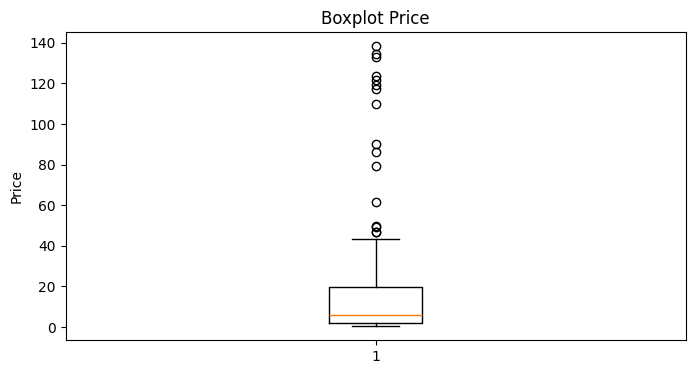

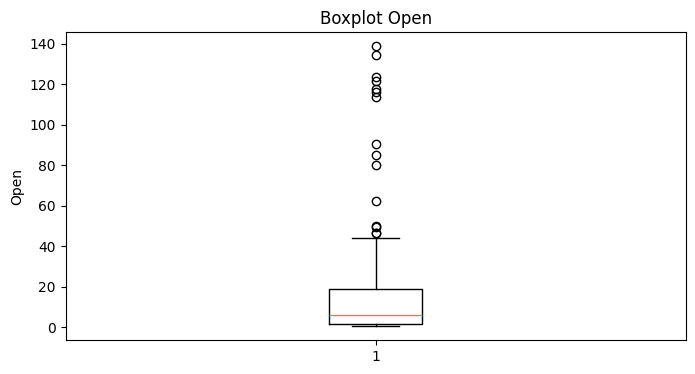

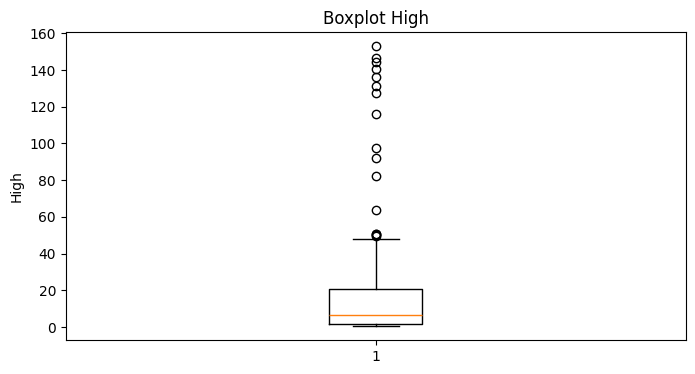

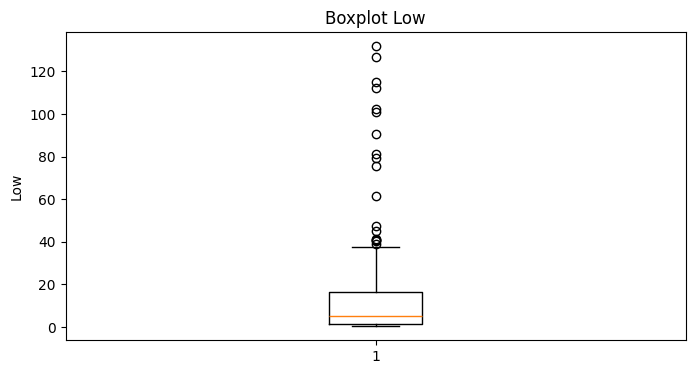

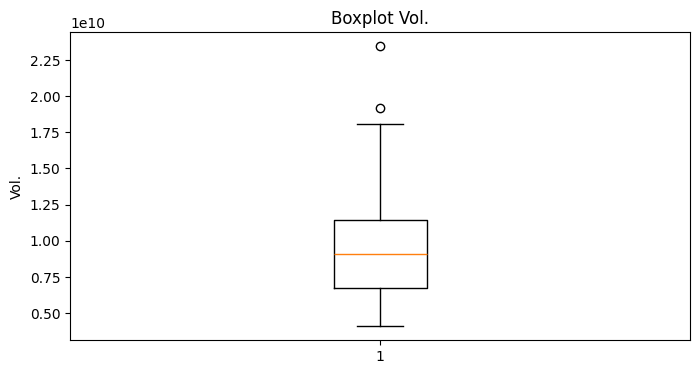

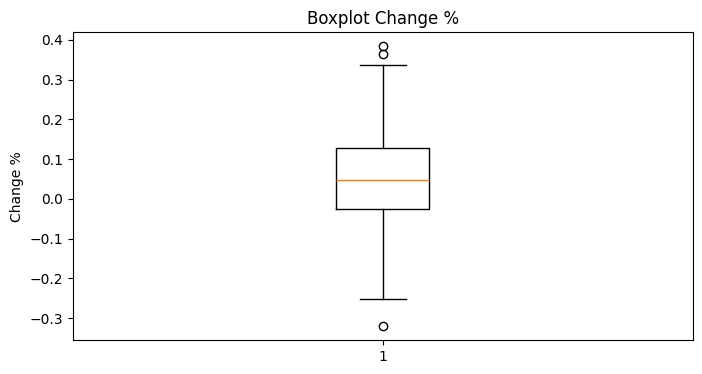

In [14]:
# Membuat boxplot untuk setiap atribut numerik
for column in numeric_columns:
    plt.figure(figsize=(8, 4))

    plt.boxplot(df_preprocessed[column].dropna())

    plt.title(f"Boxplot {column}")
    plt.ylabel(column)

    plt.show()

## Evaluasi dan Ekspor Dataset

In [15]:
# Ringkasan dataset setelah preprocessing
print("Dimensi dataset:", df_preprocessed.shape)

print("\nTipe data setiap kolom:")
print(df_preprocessed.dtypes)

print("\nMissing values:")
print(df_preprocessed.isnull().sum())

print("\nJumlah baris duplikat:")
print(df_preprocessed.duplicated().sum())

print("\nLima baris pertama:")
display(df_preprocessed.head())

print("\nLima baris terakhir:")
display(df_preprocessed.tail())

Dimensi dataset: (132, 7)

Tipe data setiap kolom:
Date        datetime64[ns]
Price              float64
Open               float64
High               float64
Low                float64
Vol.               float64
Change %           float64
dtype: object

Missing values:
Date        0
Price       0
Open        0
High        0
Low         0
Vol.        0
Change %    0
dtype: int64

Jumlah baris duplikat:
0

Lima baris pertama:


,Date,Price,Open,High,Low,Vol.,Change %
0,2014-01-01,0.39,0.40,0.41,0.38,5.420000e+09,-0.0250
1,2014-01-02,0.46,0.40,0.48,0.38,7.720000e+09,0.1795
2,2014-01-03,0.45,0.45,0.47,0.44,7.220000e+09,-0.0217
3,2014-01-04,0.46,0.46,0.49,0.45,6.940000e+09,0.0222
4,2014-01-05,0.47,0.47,0.48,0.44,5.610000e+09,0.0217



Lima baris terakhir:


,Date,Price,Open,High,Low,Vol.,Change %
127,2024-01-08,119.37,117.53,131.26,90.69,8.110000e+09,0.0201
128,2024-01-09,121.44,116.01,127.67,100.95,6.270000e+09,0.0173
129,2024-01-10,132.76,121.76,144.42,115.14,5.630000e+09,0.0932
130,2024-01-11,138.25,134.70,152.89,131.80,4.500000e+09,0.0414
131,2024-01-12,134.29,138.83,146.54,126.86,4.090000e+09,-0.0286


In [16]:
# Menyimpan dataset hasil preprocessing ke Excel
output_file = "NVIDIA_Stock_Preprocessed.xlsx"

df_preprocessed.to_excel(
    output_file,
    index=False
)

print("Dataset berhasil disimpan:", output_file)

Dataset berhasil disimpan: NVIDIA_Stock_Preprocessed.xlsx


## Pemeriksaan Data

In [17]:
# Memeriksa hasil transformasi volume
print("Tipe data Vol.:", df_preprocessed["Vol."].dtype)

print("\nContoh data volume:")
display(df_preprocessed[["Vol."]].head(10))

print("\nMissing values pada Vol.:",
      df_preprocessed["Vol."].isna().sum())

Tipe data Vol.: float64

Contoh data volume:


,Vol.
0,5.420000e+09
1,7.720000e+09
2,7.220000e+09
3,6.940000e+09
4,5.610000e+09
5,5.280000e+09
6,6.270000e+09
7,6.080000e+09
8,5.510000e+09
9,6.610000e+09



Missing values pada Vol.: 0


In [18]:
# Mengonversi kolom Date menjadi format datetime
df_preprocessed["Date"] = pd.to_datetime(
    df_preprocessed["Date"],
    errors="coerce"
)

# Memeriksa tanggal yang tidak valid
print("Jumlah tanggal tidak valid:",
      df_preprocessed["Date"].isna().sum())

# Memeriksa rentang tanggal
print("Tanggal paling awal:",
      df_preprocessed["Date"].min())

print("Tanggal paling akhir:",
      df_preprocessed["Date"].max())

# Memeriksa konsistensi harga saham
invalid_prices = df_preprocessed[
    (df_preprocessed["High"] < df_preprocessed["Low"]) |
    (df_preprocessed["Open"] < df_preprocessed["Low"]) |
    (df_preprocessed["Open"] > df_preprocessed["High"]) |
    (df_preprocessed["Price"] < df_preprocessed["Low"]) |
    (df_preprocessed["Price"] > df_preprocessed["High"])
]

print("Jumlah baris dengan ketidakkonsistenan harga:",
      len(invalid_prices))

display(invalid_prices)

Jumlah tanggal tidak valid: 0
Tanggal paling awal: 2014-01-01 00:00:00
Tanggal paling akhir: 2024-01-12 00:00:00
Jumlah baris dengan ketidakkonsistenan harga: 0


,Date,Price,Open,High,Low,Vol.,Change %


## Sorting data berdasarkan tanggal

In [19]:
# Mengurutkan data berdasarkan tanggal dari terlama ke terbaru
df_preprocessed = df_preprocessed.sort_values(
    by="Date",
    ascending=True
).reset_index(drop=True)

# Memeriksa hasil pengurutan
print("5 data pertama setelah pengurutan:")
display(df_preprocessed.head())

print("\n5 data terakhir setelah pengurutan:")
display(df_preprocessed.tail())

# Memeriksa apakah tanggal sudah terurut
print(
    "\nTanggal sudah terurut:",
    df_preprocessed["Date"].is_monotonic_increasing
)

5 data pertama setelah pengurutan:


,Date,Price,Open,High,Low,Vol.,Change %
0,2014-01-01,0.39,0.40,0.41,0.38,5.420000e+09,-0.0250
1,2014-01-02,0.46,0.40,0.48,0.38,7.720000e+09,0.1795
2,2014-01-03,0.45,0.45,0.47,0.44,7.220000e+09,-0.0217
3,2014-01-04,0.46,0.46,0.49,0.45,6.940000e+09,0.0222
4,2014-01-05,0.47,0.47,0.48,0.44,5.610000e+09,0.0217



5 data terakhir setelah pengurutan:


,Date,Price,Open,High,Low,Vol.,Change %
127,2024-01-08,119.37,117.53,131.26,90.69,8.110000e+09,0.0201
128,2024-01-09,121.44,116.01,127.67,100.95,6.270000e+09,0.0173
129,2024-01-10,132.76,121.76,144.42,115.14,5.630000e+09,0.0932
130,2024-01-11,138.25,134.70,152.89,131.80,4.500000e+09,0.0414
131,2024-01-12,134.29,138.83,146.54,126.86,4.090000e+09,-0.0286



Tanggal sudah terurut: True


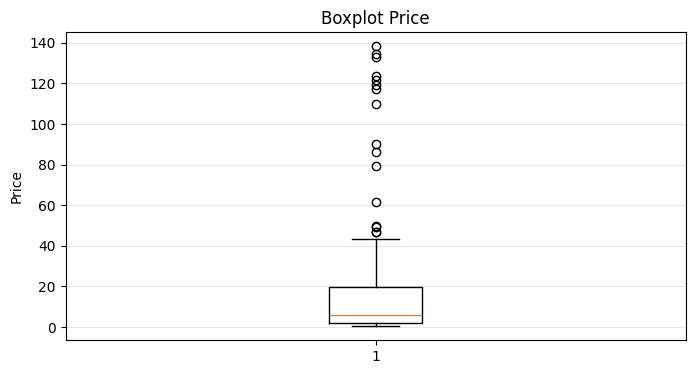

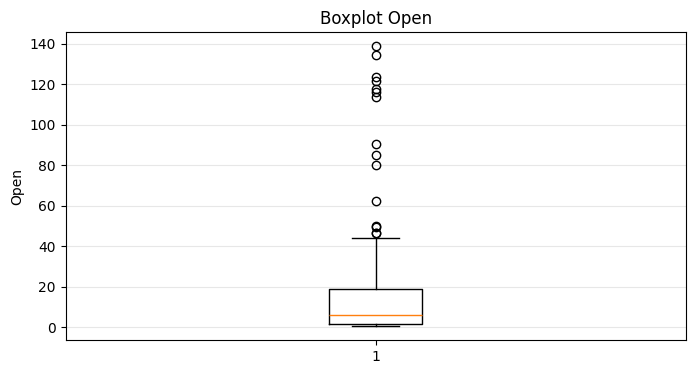

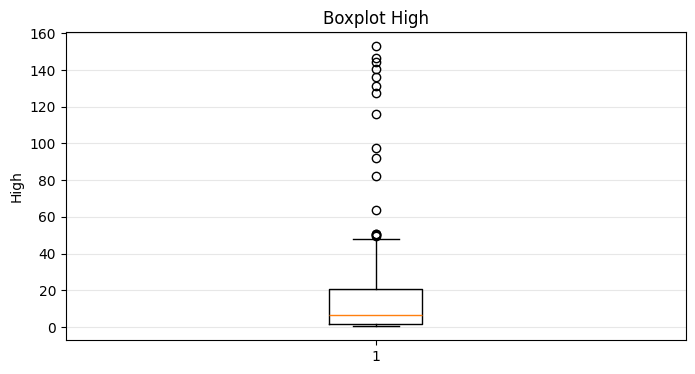

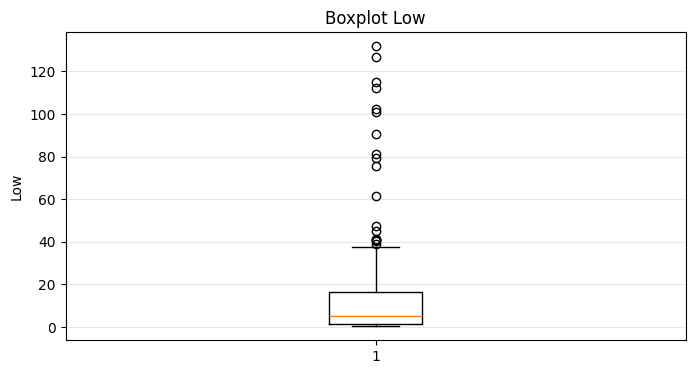

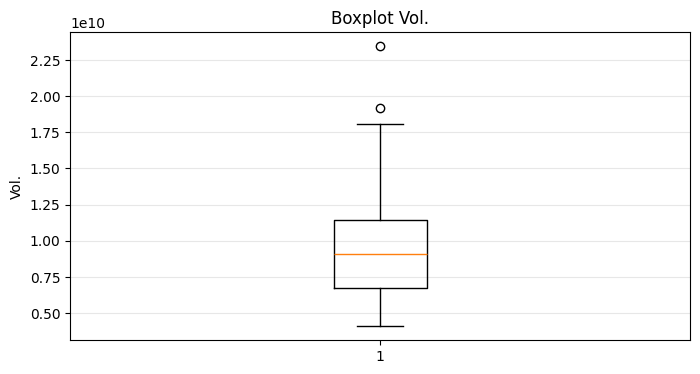

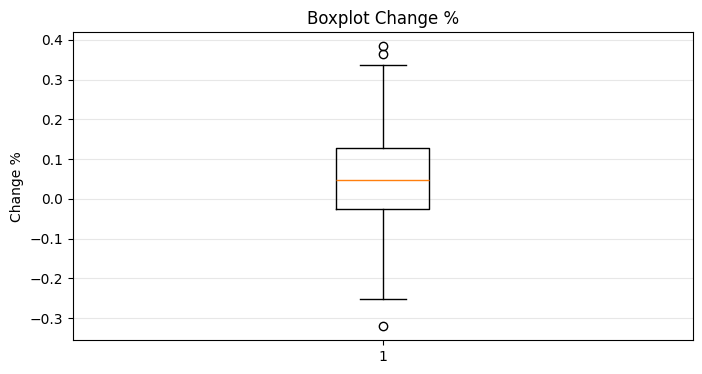

In [20]:
import matplotlib.pyplot as plt

# Kolom numerik yang akan diperiksa
kolom_outlier = [
    "Price",
    "Open",
    "High",
    "Low",
    "Vol.",
    "Change %"
]

# Menampilkan boxplot setiap variabel
for kolom in kolom_outlier:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df_preprocessed[kolom].dropna())
    plt.title(f"Boxplot {kolom}")
    plt.ylabel(kolom)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

In [21]:
# Menghitung batas bawah, batas atas, dan jumlah outlier
hasil_outlier = []

for kolom in kolom_outlier:
    Q1 = df_preprocessed[kolom].quantile(0.25)
    Q3 = df_preprocessed[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df_preprocessed[kolom] < batas_bawah) |
        (df_preprocessed[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "Variabel": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jumlah_outlier
    })

tabel_outlier = pd.DataFrame(hasil_outlier)

display(tabel_outlier.round(3))

,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Price,1.762000e+00,1.951000e+01,1.774800e+01,-2.485900e+01,4.613100e+01,16
1,Open,1.665000e+00,1.896200e+01,1.729800e+01,-2.428100e+01,4.490900e+01,15
2,High,1.798000e+00,2.069200e+01,1.889500e+01,-2.654500e+01,4.903500e+01,16
3,Low,1.550000e+00,1.639300e+01,1.484300e+01,-2.071400e+01,3.865600e+01,18
4,Vol.,6.710000e+09,1.142750e+10,4.717500e+09,-3.662500e+08,1.850375e+10,2
5,Change %,-2.600000e-02,1.290000e-01,1.550000e-01,-2.590000e-01,3.620000e-01,3


In [22]:
# Memeriksa ukuran dataset
print("Ukuran dataset:", df_preprocessed.shape)

# Memeriksa tipe data
print("\nTipe data setiap kolom:")
print(df_preprocessed.dtypes)

# Memeriksa missing values
print("\nMissing values:")
print(df_preprocessed.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah data duplikat:",
      df_preprocessed.duplicated().sum())

# Memeriksa urutan tanggal
print("\nTanggal sudah terurut:",
      df_preprocessed["Date"].is_monotonic_increasing)

# Menampilkan 5 baris pertama
print("\nContoh dataset setelah preprocessing:")
display(df_preprocessed.head())

Ukuran dataset: (132, 7)

Tipe data setiap kolom:
Date        datetime64[ns]
Price              float64
Open               float64
High               float64
Low                float64
Vol.               float64
Change %           float64
dtype: object

Missing values:
Date        0
Price       0
Open        0
High        0
Low         0
Vol.        0
Change %    0
dtype: int64

Jumlah data duplikat: 0

Tanggal sudah terurut: True

Contoh dataset setelah preprocessing:


,Date,Price,Open,High,Low,Vol.,Change %
0,2014-01-01,0.39,0.40,0.41,0.38,5.420000e+09,-0.0250
1,2014-01-02,0.46,0.40,0.48,0.38,7.720000e+09,0.1795
2,2014-01-03,0.45,0.45,0.47,0.44,7.220000e+09,-0.0217
3,2014-01-04,0.46,0.46,0.49,0.45,6.940000e+09,0.0222
4,2014-01-05,0.47,0.47,0.48,0.44,5.610000e+09,0.0217


In [23]:
# Menyimpan dataset ke Excel
df_preprocessed.to_excel(
    "NVIDIA_Stock_Preprocessed.xlsx",
    index=False
)

# Menyimpan dataset ke CSV
df_preprocessed.to_csv(
    "NVIDIA_Stock_Preprocessed.csv",
    index=False
)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


## Kesimpulan

Preprocessing dilakukan terhadap dataset historis harga saham NVIDIA periode 1
Januari 2014 hingga 12 Januari 2024. Tahapan yang dilakukan meliputi pemeriksaan struktur data, identifikasi nilai kosong dan duplikat, konversi kolom volume transaksi menjadi tipe numerik, konversi kolom tanggal ke format datetime, pemeriksaan konsistensi harga saham, pengurutan data berdasarkan tanggal, serta deteksi outlier menggunakan metode Interquartile Range (IQR).

Hasil pemeriksaan menunjukkan bahwa dataset tidak memiliki nilai kosong maupun data duplikat. Selain itu, tidak ditemukan tanggal yang tidak valid atau ketidakkonsistenan pada variabel harga saham. Deteksi outlier menunjukkan adanya sejumlah nilai ekstrem pada variabel harga, volume transaksi, dan persentase perubahan harga. Nilai-nilai tersebut tidak langsung dihapus karena dapat mencerminkan fluktuasi pasar yang sebenarnya. Dengan demikian, dataset telah melalui tahapan preprocessing dan siap digunakan untuk analisis data lebih lanjut.
